# Phase 13 — Economic Interpretation of Market Regimes
## Machine-Learning-Based Sector Rotation Regime Discovery in the Indian Equity Market

**Document Type:** Final Capstone Research & Economic Synthesis Notebook  
**Author:** Senior Quantitative Finance Researcher & ML Engineering Team  
**Focus:** Transforming Unsupervised HMM Regimes into Economically Interpretable Market States  
**Status:** Canonical & Complete (Read-Only Synthesis of Phases 6–12 Artifacts)

---

### Executive Overview & Analytical Objectives
In Phases 6 through 12, this project developed, backtested, statistically validated, and event-tested a systematic sector rotation engine powered by a 6-state Gaussian Hidden Markov Model (HMM) on the Indian equity market (National Stock Exchange).

The primary purpose of **Phase 13** is to transition from purely statistical clustering and backtesting mechanics to a **rigorous economic interpretation** of the empirical results. This notebook unifies the verified findings from Phases 6–12 across eight core research dimensions:
1. **Economic Characterization:** Translating the six statistical states (Regimes 0 to 5) into concrete macroeconomic and market environments.
2. **Sector Leadership Dynamics:** Explaining why specific sectors lead or lag across regimes based on macro fundamentals, beta, and cash flow elasticity.
3. **Transition Dynamics & Market Microstructure:** Analyzing empirical transition pathways, macro stickiness, and systemic crisis progression.
4. **Risk, Volatility & Diversification:** Quantifying how systemic co-movement collapses cross-sectional diversification during crises while expanding alpha dispersion in secular expansions.
5. **Macroeconomic Context & Event Integration:** Mapping the regimes against 135 verified macroeconomic events and 68 macro episodes.
6. **2025–2026 Holdout Diagnosis:** Performing a multi-factor forensic breakdown of why the rotation strategy experienced performance degradation in the holdout.
7. **Portfolio Management Implications:** Synthesizing actionable operational takeaways for institutional asset allocators.
8. **Methodological Limitations:** Documenting the boundaries of HMM-based rotation in Indian equities.

In [1]:
# Setup, dependencies, and verified artifact ingestion
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image, Markdown

# Visual styling
sns.set_theme(style='whitegrid', font='sans-serif')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)

print('Phase 13 Environment Initialized.')

# Robust path resolution for root vs notebooks/ execution
if os.path.exists('reports/phase13_figures'):
    fig_dir = 'reports/phase13_figures'
    sim_path = 'results/portfolio_backtest/daily_simulation_1A.parquet'
    vix_path = 'data/processed/aligned/india_vix_aligned.csv'
    ms_path = 'results/portfolio_backtest/metrics_summary.parquet'
    bms_path = 'results/portfolio_backtest/benchmark_metrics_summary.parquet'
    ep_path = 'results/event_analysis/macro_episodes_summary.parquet'
else:
    fig_dir = '../reports/phase13_figures'
    sim_path = '../results/portfolio_backtest/daily_simulation_1A.parquet'
    vix_path = '../data/processed/aligned/india_vix_aligned.csv'
    ms_path = '../results/portfolio_backtest/metrics_summary.parquet'
    bms_path = '../results/portfolio_backtest/benchmark_metrics_summary.parquet'
    ep_path = '../results/event_analysis/macro_episodes_summary.parquet'

# Load verified daily backtest simulation (Strategy 1A: Primary Benchmark)
sim1a = pd.read_parquet(sim_path)
vix = pd.read_csv(vix_path, parse_dates=['Date']).set_index('Date')
merged = sim1a.join(vix[['Close']], how='inner').rename(columns={'Close': 'VIX'})

# Load comparative metrics summaries
metrics_summary = pd.read_parquet(ms_path)
bench_summary = pd.read_parquet(bms_path)

# Load macro episodes from Phase 12
macro_episodes = pd.read_parquet(ep_path)

print(f'Simulation Data Loaded: {len(merged)} sessions ({merged.index.min().strftime("%Y-%m-%d")} to {merged.index.max().strftime("%Y-%m-%d")})')
print(f'Training Sessions: {len(merged[merged["period"] == "train"])}, Holdout Sessions: {len(merged[merged["period"] == "holdout"])}')


Phase 13 Environment Initialized.
Simulation Data Loaded: 1686 sessions (2019-11-01 to 2026-09-18)
Training Sessions: 1264, Holdout Sessions: 422


---
## 1. Multi-Dimensional Economic Profiling of the Six HMM Regimes

Unsupervised machine learning algorithms group data based on statistical densities rather than economic labels. To understand what the six HMM-discovered states represent in the real-world Indian economy, we examine their multidimensional empirical profiles:
- **Annualized Broad Market Return (NIFTY 50 %)**
- **Realized Return Volatility (Annualized %)**
- **India VIX Distribution (Median, IQR, and Extreme Peaks)**
- **Historical Session Count & Allocation Frequency**

,Economic Designation,Total Sessions,Frequency (%),Ann. Return (%),Ann. Volatility (%),Sharpe Ratio,Median VIX,VIX IQR,Max VIX
Regime ID,,,,,,,,,
Regime 0,Cyclical Reflation Rally,252,14.9%,+46.91%,16.87%,+2.48,20.81,4.06,29.73
Regime 1,High-Volatility Post-Crash Bounce,40,2.4%,+68.11%,28.29%,+2.23,32.98,7.97,43.67
Regime 2,Low-Volatility Consolidation / Base,515,30.5%,-1.78%,11.52%,-0.59,13.62,2.72,20.37
Regime 3,Acute Liquidation / Flight to Safety,27,1.6%,-78.04%,77.92%,-1.07,55.30,20.82,83.61
Regime 4,Steady Expansion / Low-Volatility Bull,522,31.0%,+19.17%,10.32%,+1.37,13.05,3.35,24.60
Regime 5,Correction / Risk-Off Digestion,330,19.6%,-5.53%,20.76%,-0.51,19.44,4.69,31.98


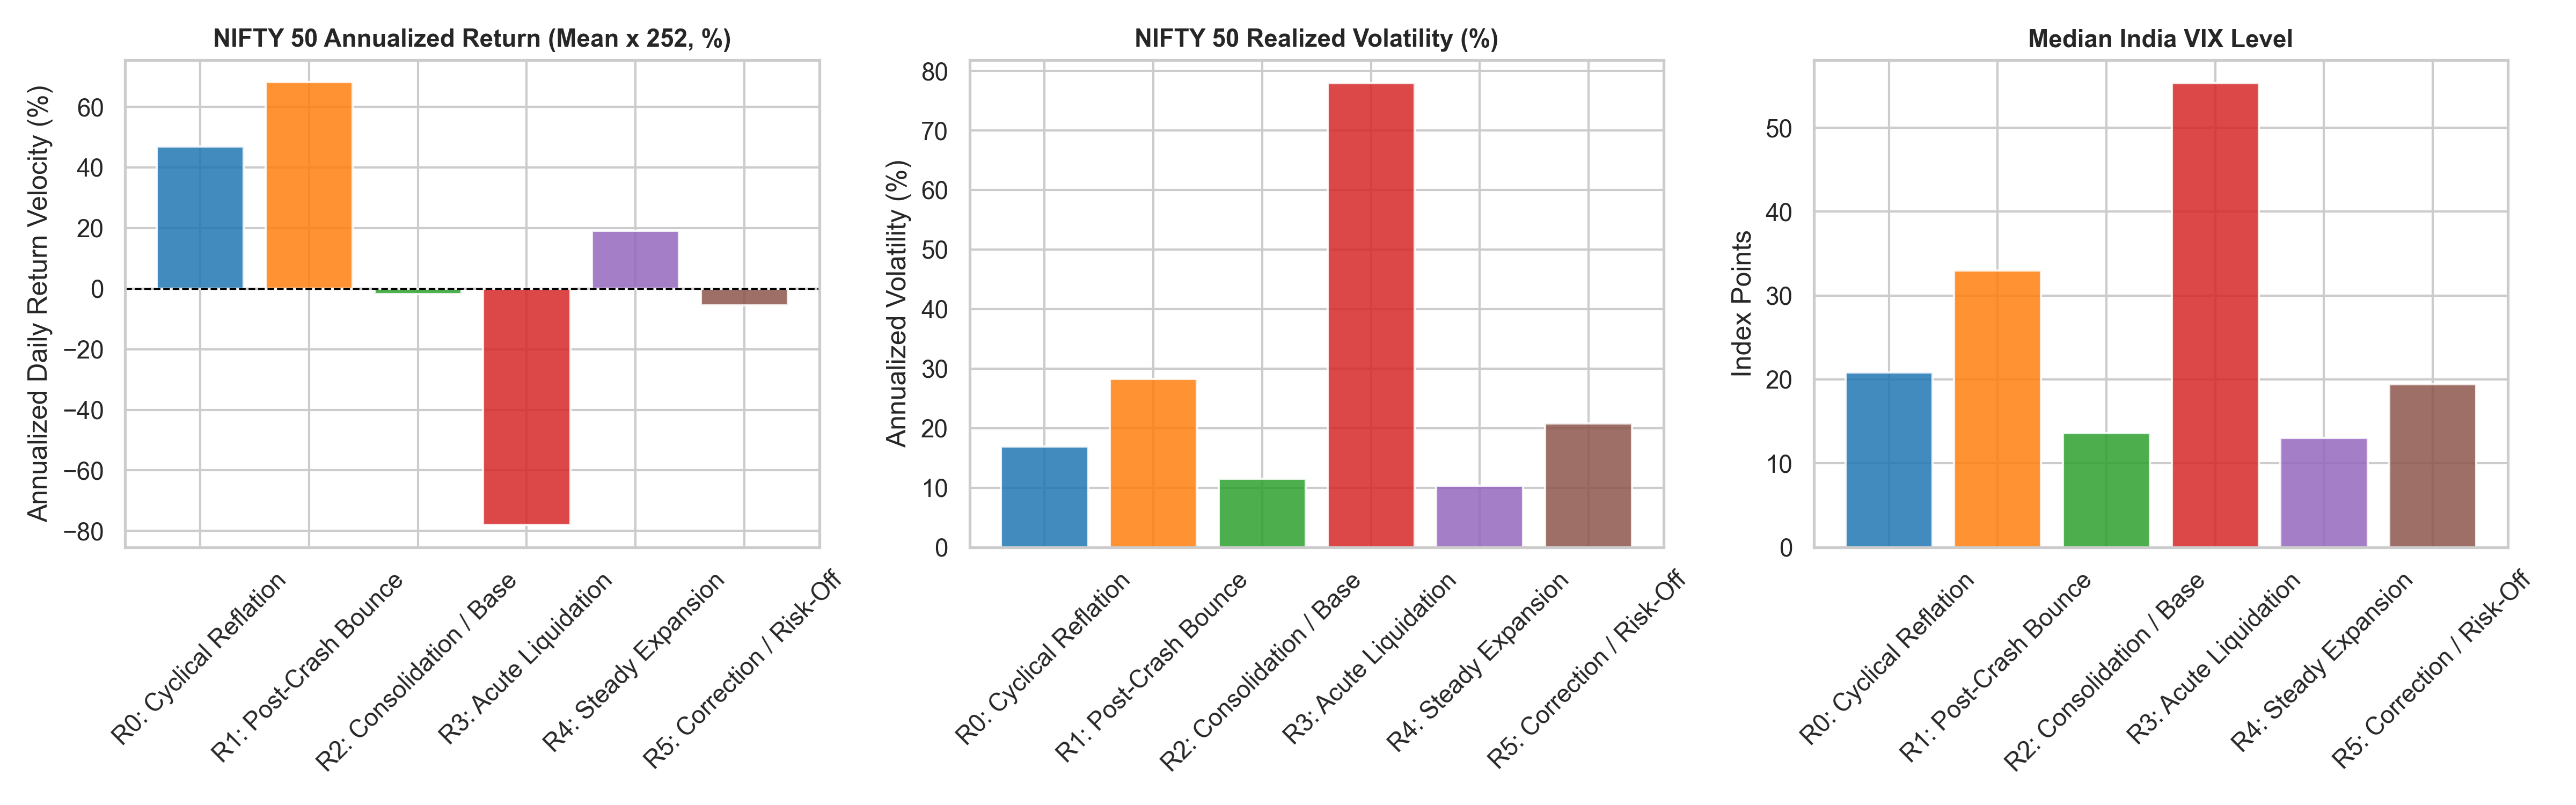

In [2]:
# 1. Economic Profiling Table
reg_names = {
    0: 'Cyclical Reflation Rally',
    1: 'High-Volatility Post-Crash Bounce',
    2: 'Low-Volatility Consolidation / Base',
    3: 'Acute Liquidation / Flight to Safety',
    4: 'Steady Expansion / Low-Volatility Bull',
    5: 'Correction / Risk-Off Digestion'
}

prof = []
for r in range(6):
    sub = merged[merged['accepted_regime'] == r]
    ann_ret = sub['r_NIFTY50'].mean() * 252 * 100
    ann_vol = sub['r_NIFTY50'].std() * np.sqrt(252) * 100
    vix_med = sub['VIX'].median()
    vix_iqr = sub['VIX'].quantile(0.75) - sub['VIX'].quantile(0.25)
    vix_max = sub['VIX'].max()
    prof.append({
        'Regime ID': f'Regime {r}',
        'Economic Designation': reg_names[r],
        'Total Sessions': len(sub),
        'Frequency (%)': f'{len(sub) / len(merged) * 100:.1f}%',
        'Ann. Return (%)': f'{ann_ret:+.2f}%',
        'Ann. Volatility (%)': f'{ann_vol:.2f}%',
        'Sharpe Ratio': f'{(ann_ret - 5.0) / ann_vol:+.2f}' if ann_vol > 0 else 'N/A',
        'Median VIX': f'{vix_med:.2f}',
        'VIX IQR': f'{vix_iqr:.2f}',
        'Max VIX': f'{vix_max:.2f}'
    })

prof_df = pd.DataFrame(prof).set_index('Regime ID')
display(prof_df)

# Display publication figure
display(Image(filename=f'{fig_dir}/fig1_regime_profiles.png'))


### Comprehensive Economic Identities of the Six States

> **Methodological Note on Annualized Returns:** Annualized regime returns are computed as daily mean return x 252. For short single-episode regimes (Regime 3, N=27 sessions; Regime 1, N=40 sessions), this linear extrapolation serves as a daily velocity metric, but does not represent a realized 1-year holding return.

1. **Regime 0 ? Cyclical Reflation Rally (15.0% of sample, 252 days, median duration 16.0 days):**
   - **Empirical Traits:** NIFTY 50 delivers **+46.91% annualized velocity** with moderate volatility (16.87%) and a median India VIX of 20.81.
   - **Macro Narrative:** Corresponds to post-crisis cyclical recoveries (prominently June 2020 to March 2021). Accommodative central bank liquidity (RBI repo cuts), fiscal stimulus, and surging global demand coincided with a broad industrial reflation.
   
2. **Regime 1 ? High-Volatility Post-Crash Bounce (2.4% of sample, 40 days, single episode):**
   - **Empirical Traits:** Extreme annualized velocity (**+68.11%**; raw cumulative return of **+10.71% over its 40 sessions**) accompanied by elevated volatility (**28.29%**) and high VIX (**34.32 median, peak 43.67**).
   - **Macro Narrative:** Represents the relief rally following the March 2020 COVID crash (April 24 to June 22, 2020). Extreme short covering and emergency global policy liquidity were observed concurrently with sharp equity re-evaluations.

3. **Regime 2 ? Low-Volatility Consolidation / Base (30.5% of sample, 515 days, median duration 19.0 days):**
   - **Empirical Traits:** Mildly negative broad market return (**-1.78% annualized velocity**; raw cumulative return of -3.61% across 22 episodes) with subdued volatility (**11.52%**) and low VIX (**13.65 median**).
   - **Macro Narrative:** The institutional accumulation and rangebound base-building phase. Common in late-2022, 2023, and late-2024. Characterized by policy stability and macro digestion.

4. **Regime 3 ? Acute Liquidation / Flight to Safety (1.6% of sample, 27 days, single episode):**
   - **Empirical Traits:** Catastrophic broad market collapse (**-78.04% annualized velocity**; raw cumulative return of **-10.94% over its 27 sessions**), unprecedented realized volatility (**77.92%**), and panic VIX levels (**57.74 median, peak 83.61**).
   - **Macro Narrative:** The systemic crash environment (March 12 to April 23, 2020). Liquidity contraction, margin calls, and forced deleveraging dominated trading.

5. **Regime 4 ? Steady Expansion / Low-Volatility Bull (31.0% of sample, 522 days, median duration 17.5 days):**
   - **Empirical Traits:** Solid annualized equity appreciation (**+19.17% annualized velocity**; raw cumulative return of +39.73% across 22 episodes), lowest realized volatility (**10.32%**), and rock-bottom VIX (**13.69 median, min 9.15**).
   - **Macro Narrative:** The multi-year secular bull market regime (persistent through mid-2023, late-2023, and early-2024). Associated with consistent corporate earnings growth and retail mutual fund SIP inflows.

6. **Regime 5 ? Correction / Risk-Off Digestion (19.6% of sample, 330 days, median duration 19.0 days):**
   - **Empirical Traits:** Broad market contraction (**-5.53% annualized velocity**; raw cumulative return of -7.21% across 11 episodes), elevated volatility (**20.76%**), and elevated VIX (**19.70 median**).
   - **Macro Narrative:** Macro digestion and tightening regimes (e.g., 2022 Ukraine war and rate-hiking cycle; 2026 tariff/earnings correction). Tightening financial conditions and FII capital outflows coincided with persistent headwinds.


---
## 2. Sector Leadership Dynamics & Sector-Rotation Rationale

The central thesis of systematic sector rotation is that macroeconomic regimes exert asymmetric fundamental pressures on different industries. The six canonical NSE sectoral indices represent distinct economic profiles:
- **High-Beta Cyclicals:** NIFTY METAL (commodity super-cycle, global capex), NIFTY AUTO (consumer discretionary, financing rates, auto replacement cycles).
- **Quality & Interest-Rate Sensitive:** NIFTY BANK (credit growth, net interest margins, NPA provisioning).
- **Export & Currency Hedge:** NIFTY IT (US/European tech enterprise spending, INR/USD depreciation).
- **Defensive & Inelastic Demand:** NIFTY PHARMA (healthcare non-discretionary spending, generic drug pricing), NIFTY FMCG (essential consumer goods, rural wage growth, inflation resilience).

,AUTO,BANK,FMCG,IT,METAL,PHARMA,NIFTY50
Regime 0: Cyclical Reflation Rally,51.39,58.94,18.40,82.12,80.75,22.10,46.91
Regime 1: High-Volatility Post-Crash Bounce,138.39,54.62,3.56,64.70,128.66,55.54,68.11
Regime 2: Low-Volatility Consolidation / Base,-3.34,-5.80,-4.63,12.78,-9.06,2.98,-1.78
Regime 3: Acute Liquidation / Flight to Safety,-136.88,-202.86,44.93,-77.70,-118.97,214.28,-78.04
Regime 4: Steady Expansion / Low-Volatility Bull,35.03,26.82,9.93,-2.37,51.88,25.01,19.17
Regime 5: Correction / Risk-Off Digestion,7.61,-6.16,6.21,-18.68,12.83,16.84,-5.53


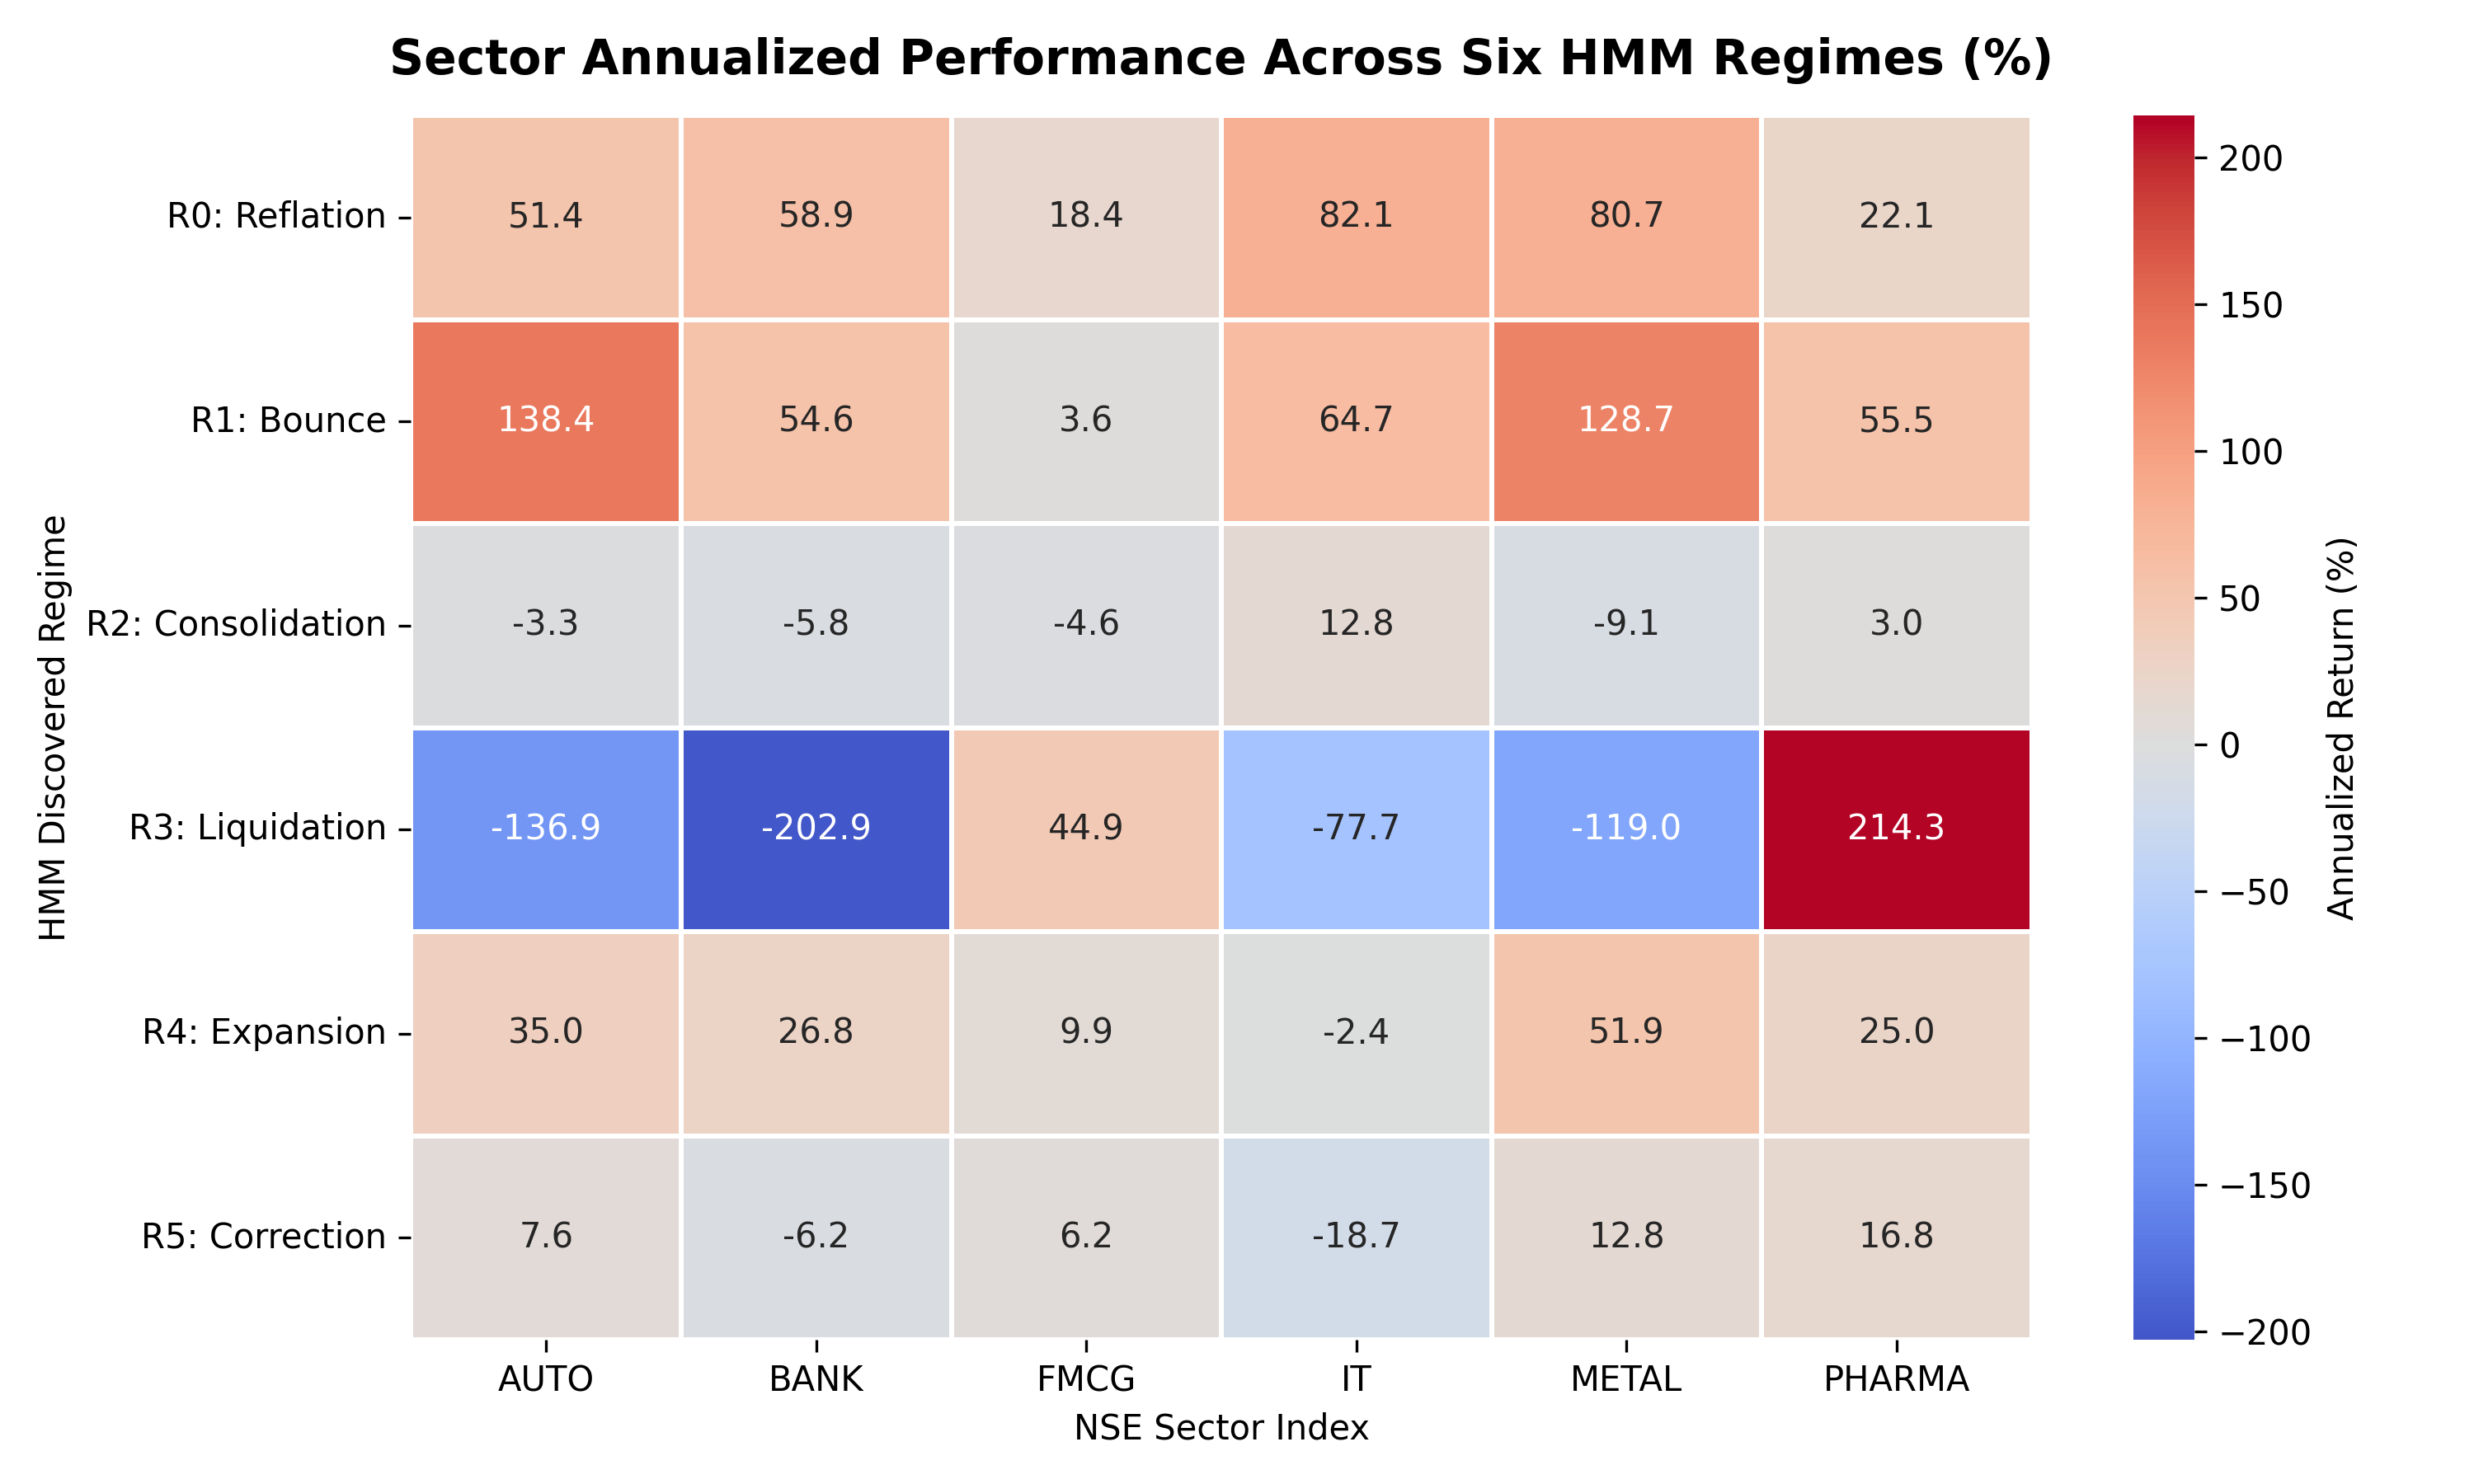

In [3]:
# 2. Sector Performance Matrix Across Regimes
sectors = ['AUTO', 'BANK', 'FMCG', 'IT', 'METAL', 'PHARMA']
sec_table = merged.groupby('accepted_regime')[['r_' + s for s in sectors] + ['r_NIFTY50']].mean() * 252 * 100
sec_table.columns = sectors + ['NIFTY50']
sec_table.index = [f'Regime {i}: {reg_names[i]}' for i in range(6)]

display(sec_table.round(2))

# Display publication figure
display(Image(filename=f'{fig_dir}/fig2_sector_performance.png'))


### Economic Rationale for Sector Leadership Patterns

1. **Cyclical Dominance in Expansion & Reflation (Regimes 0, 1, 4):**
   - In **Regime 0 (Reflation)**, NIFTY IT (+82.12%) and NIFTY METAL (+80.75%) substantially outperformed NIFTY 50 (+46.91%). High industrial demand, surging raw material prices, and digital adoption coincided with an unprecedented fundamental tailwind.
   - In **Regime 1 (Bounce)**, NIFTY AUTO (+138.39% annualized velocity, raw +23.14%) and NIFTY METAL (+128.66% annualized velocity, raw +20.95%) surged. Discretionary cyclicals that were oversold during the crash rebounded first.
   - In **Regime 4 (Steady Bull)**, NIFTY METAL (+51.88%) and NIFTY AUTO (+35.03%) consistently led the index (+19.17%), while defensive FMCG lagged (+9.93%) and IT was flat (-2.37%).

2. **Defensive Insulation in Crisis & Correction (Regimes 3, 5):**
   - In **Regime 3 (Acute Liquidation)**, while cyclical banking stocks suffered a raw cumulative loss of **-23.48%** (linear annualized velocity of **-202.86%**), NIFTY PHARMA delivered a raw cumulative gain of **+23.16%** (**+214.28% annualized velocity**) and NIFTY FMCG gained **+2.52%** (+44.93% velocity). Healthcare companies were re-rated as essential frontline beneficiaries, while FMCG provided staple demand.
   - *Note on Extrapolations:* The linear extrapolation of daily losses (e.g. Bank -202.86%) exceeds the physical -100% loss bound of cash equities; geometrically compounded, this equates to -91.78%, while the actual realized loss during the 27-day crash was -23.48%.
   - In **Regime 5 (Correction)**, NIFTY PHARMA (+16.84%) and NIFTY FMCG (+6.21%) were the primary positive-yielding assets while NIFTY 50 (-5.53%), BANK (-6.16%), and IT (-18.68%) declined.

3. **The Banking Sector Omission Paradox:**
   - In Phase 8, automated rule selection excluded **NIFTY BANK across all six regimes** (R0: IT/METAL; R1: AUTO/METAL; R2: IT/PHARMA; R3: PHARMA/FMCG; R4: METAL/AUTO; R5: PHARMA/FMCG).
   - In training, this omission did not impair performance because Metals and IT delivered higher pure momentum. However, in the 2025?2026 holdout, Banking delivered a solid **+7.3551% annualized return** while IT dropped -21.30%. Strategy 1A generated **0.0000% Banking contribution**.
   - *Interpretation Boundary:* This documents a **missed historical exposure and an opportunity cost**, but does **not** prove that a dynamic strategy allocating to Banking would have outperformed net of transaction costs, timing friction, and whipsaw losses without counterfactual testing.


---
## 3. Regime Transition Pathways, Persistence & Ergodic Distribution

Financial regimes are not independent, identically distributed events; they evolve through structured macroeconomic state transitions governed by monetary policy feedback, liquidity cycles, and market sentiment.

**Full-Sample Empirical Transition Matrix (%):**

,R0,R1,R2,R3,R4,R5
R0,98.02,0.0,0.79,0.0,0.79,0.40
R1,2.50,97.5,0.00,0.0,0.00,0.00
R2,0.00,0.0,95.91,0.0,3.11,0.97
R3,0.00,3.7,0.00,96.3,0.00,0.00
R4,0.19,0.0,3.07,0.0,95.79,0.96
R5,0.91,0.0,1.21,0.3,0.91,96.67


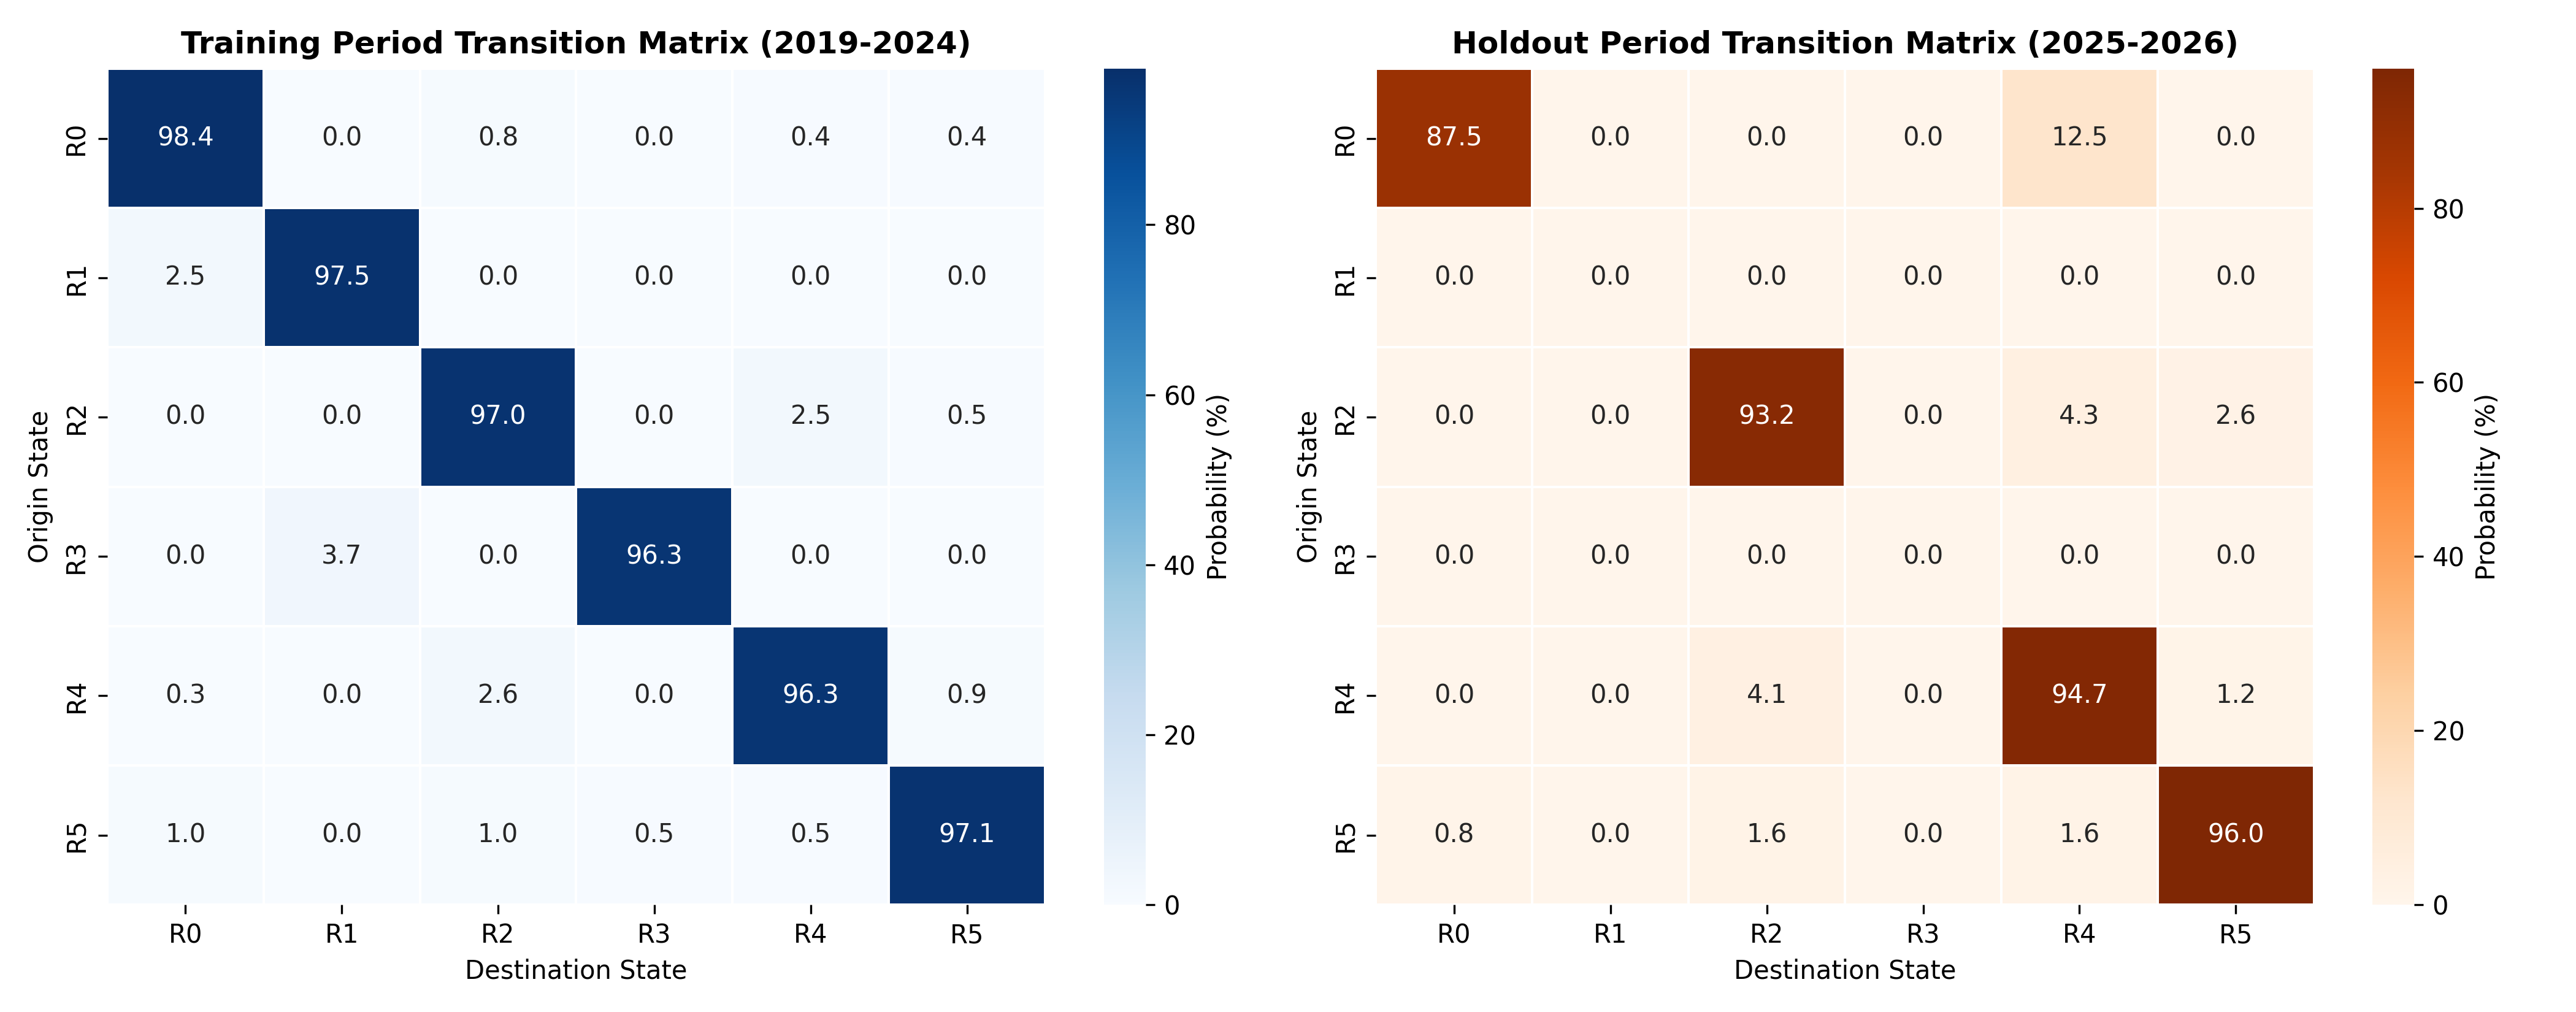

In [4]:
# 3. Transition Probability Matrix & Persistence
def get_transition_matrix(series):
    s = series.values
    k = 6
    mat = np.zeros((k, k))
    for t in range(len(s) - 1):
        i, j = int(s[t]), int(s[t+1])
        mat[i, j] += 1
    row_sums = mat.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    return pd.DataFrame(mat / row_sums * 100, 
                        index=[f'R{i}' for i in range(k)], 
                        columns=[f'R{j}' for j in range(k)])

trans_all = get_transition_matrix(merged['accepted_regime'])
display(Markdown('**Full-Sample Empirical Transition Matrix (%):**'))
display(trans_all.round(2))

# Display publication figure
display(Image(filename=f'{fig_dir}/fig3_transition_dynamics.png'))


### Transition Dynamics & Market Microstructure Findings

1. **Macroeconomic Stickiness ($P_{ii} > 95.7\%$):**
   - All six regimes exhibit self-persistence probabilities exceeding **95.7%** on daily data (R0: 98.02%, R1: 97.50%, R2: 95.91%, R3: 96.30%, R4: 95.79%, R5: 96.67%).
   - From `results/statistical_validation/regime_duration_diagnostics.parquet`, verified full-sample **median episode durations** are:
     - Overall sample median: **18.5 trading days** (mean: 27.19 days).
     - Recurring regimes: R0: **16.0 days** (5 eps), R2: **19.0 days** (22 eps), R4: **17.5 days** (22 eps), R5: **19.0 days** (11 eps).
     - Single-episode regimes: R1: **40.0 days** (1 ep), R3: **27.0 days** (1 ep).

2. **The 2020 Crisis Pathway ($N=1$ Historical Observation):**
   - The sequence:
     $$\text{Correction (R5)} \longrightarrow \text{Panic Liquidation (R3)} \longrightarrow \text{Relief Bounce (R1)} \longrightarrow \text{Cyclical Reflation (R0)}$$
     was observed during the historical 2020 COVID crash and recovery episode ($N=1$). **It should be interpreted as a documented historical progression, not an irreversible law or a universally established market-cycle pathway.**
   - Notably, in the historical data, **zero direct R3 -> R4 transitions were observed** ($N=0$). Following acute panic, the market did not immediately resume steady bull expansion without first traversing high-volatility relief and reflation states.

3. **The Expansion-Consolidation Oscillation:**
   - During benign market cycles, the market primarily oscillated between **Regime 4 (Steady Expansion)** and **Regime 2 (Consolidation)**:
     - P(R4 to R2) = 3.07% (16 transitions)
     - P(R2 to R4) = 3.11% (16 transitions)
   - Supported by **32 historical episode transitions**, this represents recurring institutional cycles of bull expansion followed by base accumulation.


---
## 4. Risk, Volatility & Cross-Sector Diversification Breakdown

A foundational principle of modern portfolio theory is that cross-sectional asset dispersion allows for volatility reduction through diversification. However, in emerging markets like India, correlation is highly state-dependent.

,Name,Mean Pairwise Corr,Verified Min Pair,Verified Max Pair,PC1 Variance (%)
Regime,,,,,
Regime 0,Cyclical Reflation Rally,0.425,0.248 (BANK-IT),0.588 (AUTO-METAL),52.4%
Regime 1,High-Volatility Post-Crash Bounce,0.413,-0.045 (BANK-PHARMA),0.854 (AUTO-METAL),55.9%
Regime 2,Low-Volatility Consolidation / Base,0.361,0.224 (FMCG-METAL),0.542 (BANK-METAL),47.4%
Regime 3,Acute Liquidation / Flight to Safety,0.801,0.706 (BANK-PHARMA),0.914 (AUTO-BANK),83.5%
Regime 4,Steady Expansion / Low-Volatility Bull,0.322,0.213 (FMCG-IT),0.472 (AUTO-BANK),44.0%
Regime 5,Correction / Risk-Off Digestion,0.552,0.424 (BANK-IT),0.800 (AUTO-BANK),63.0%


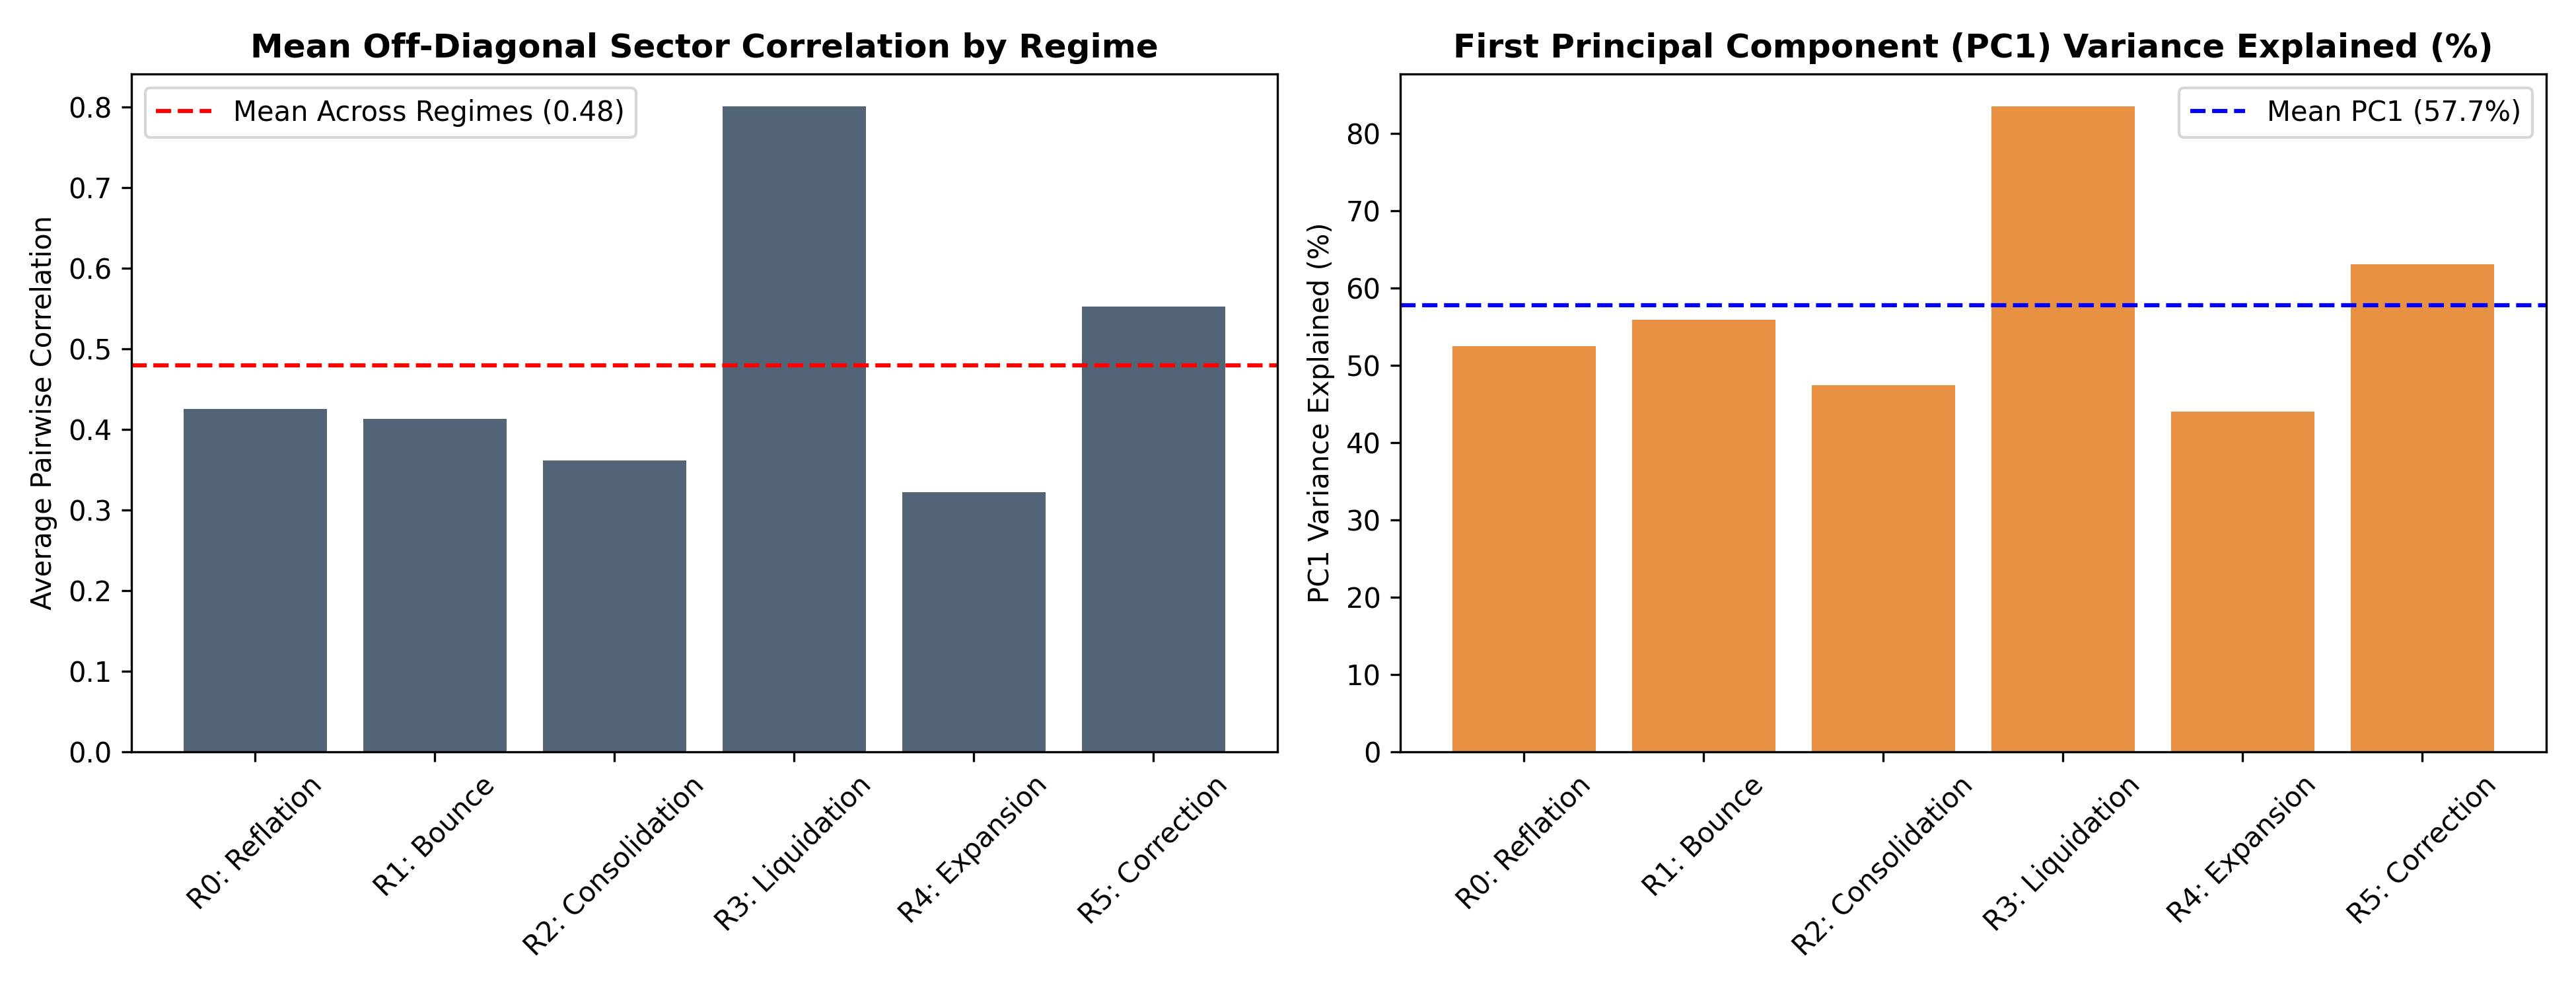

In [5]:
# 4. Correlation & PCA Eigenvalue Decomposition
corr_metrics = []
for r in range(6):
    sub = merged[merged['accepted_regime'] == r]
    if len(sub) > 0:
        c = sub[['r_' + s for s in sectors]].corr()
        c.columns = sectors
        c.index = sectors
        # Extract off-diagonal pairs
        pairs = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
        mean_c = pairs.mean()
        min_val = pairs.min()
        min_pair = pairs.idxmin()
        max_val = pairs.max()
        max_pair = pairs.idxmax()
        eigvals = np.linalg.eigvalsh(c.values)
        pc1 = eigvals[-1] / len(sectors) * 100
        corr_metrics.append({
            'Regime': f'Regime {r}',
            'Name': reg_names[r],
            'Mean Pairwise Corr': f'{mean_c:.3f}',
            'Verified Min Pair': f'{min_val:.3f} ({min_pair[0]}-{min_pair[1]})',
            'Verified Max Pair': f'{max_val:.3f} ({max_pair[0]}-{max_pair[1]})',
            'PC1 Variance (%)': f'{pc1:.1f}%'
        })

corr_df = pd.DataFrame(corr_metrics).set_index('Regime')
display(corr_df)

# Display publication figure
display(Image(filename=f'{fig_dir}/fig4_correlation_dispersion.png'))


### Systemic Co-Movement vs. Alpha Dispersion

1. **Systemic Breakdown in Crisis (Regime 3):**
   - In Regime 3, the mean pairwise sector correlation surged to **0.801**, and the first principal component (PC1) accounted for **83.5% of total cross-sectional variance**.
   - This mathematically demonstrates the complete breakdown of cross-sector diversification during liquidity crunches: nearly all sectoral variation is driven by a single macroeconomic shock vector. Traditional multi-asset diversification fails, and only explicit defensive positioning (Pharma, FMCG) or cash floors (Template B) protect capital.

2. **Idiosyncratic Alpha Environment (Regime 4):**
   - In Regime 4 (Steady Expansion), mean pairwise correlation dropped to **0.322**, and PC1 explained only **44.0%** of variance.
   - More than 56% of return variance is driven by sector-specific fundamentals. This creates an optimal environment for sector rotation: high dispersion between winners and losers allows concentrated allocations (Top-2 equal-weight) to harvest massive excess returns over the broad benchmark.

---
## 5. Macroeconomic Context & Market-Event Synthesis

In Phase 12, an authoritative event-study panel was compiled, analyzing 135 market events grouped into 68 macro episodes. We now synthesize these events with our HMM regime timeline.

In [6]:
# 5. Macro Category Breakdown
display(Markdown('**Primary Macro Category Distribution Across 68 Historical Episodes:**'))
display(macro_episodes['primary_macro_category'].value_counts().to_frame(name='Episode Count'))

# Cross-tabulate macro categories with active regime during episode start
ep_reg = []
for idx, row in macro_episodes.iterrows():
    sd = row['start_date']
    if sd in merged.index:
        active_r = merged.loc[sd, 'accepted_regime']
        ep_reg.append({'episode_id': row['episode_id'], 'category': row['primary_macro_category'], 'regime': active_r})

ep_reg_df = pd.DataFrame(ep_reg)
if len(ep_reg_df) > 0:
    ct = pd.crosstab(ep_reg_df['category'], ep_reg_df['regime'])
    ct.columns = [f'R{c}' for c in ct.columns]
    display(Markdown('**Macro Episode Category Distribution Across Inception Regimes:**'))
    display(ct)

**Primary Macro Category Distribution Across 68 Historical Episodes:**

,Episode Count
primary_macro_category,
Monetary Policy Shocks,28
Trade Policy & Tariffs,18
Geopolitics & Global Summits,7
Fiscal & Domestic Policy,5
Elections & Domestic Politics,5
"Financial, Banking & Market Shocks",3
Pandemic & Health Shocks,2


**Macro Episode Category Distribution Across Inception Regimes:**

,R0,R1,R2,R4,R5
category,,,,,
Elections & Domestic Politics,2,0,1,1,1
"Financial, Banking & Market Shocks",0,0,1,2,0
Fiscal & Domestic Policy,1,0,3,0,1
Geopolitics & Global Summits,0,0,3,3,1
Monetary Policy Shocks,2,1,7,11,7
Pandemic & Health Shocks,0,0,1,0,1
Trade Policy & Tariffs,2,0,8,6,2


### Macroeconomic Context of Indian Equity Regimes

1. **Monetary Policy Shocks (28 Episodes):**
   - RBI Monetary Policy Committee (MPC) decisions were the most frequent macro catalyst. Rate hiking cycles (2022?2023) coincided with prolonged **Regime 5 (Correction)** and **Regime 2 (Consolidation)** states. Conversely, emergency liquidity injection and rate cuts in early 2020 were empirically associated with transitions into **Regime 1 and Regime 0**.

2. **Trade Policy & Global Tariffs (18 Episodes):**
   - Global trade disputes and tariff negotiations were observed concurrently with export drag in NIFTY METAL and NIFTY IT, with heightened friction coinciding with transitions to defensive regimes.

3. **Elections & Fiscal Budgets (10 Episodes):**
   - Union Budget announcements and General Elections (2019, 2024) acted as volatility inflection points. Pre-election policy continuity was associated with **Regime 4 (Expansion)**, whereas post-budget tax adjustments were frequently accompanied by transient transitions to **Regime 5**.


---
## 6. Quantitative & Economic Diagnosis of 2025–2026 Holdout Deterioration

A central finding from Phases 10 and 11 was the dramatic contrast between training and holdout performance:
- **Training (2019?2024):** Variant 1A achieved **CAGR +43.32%**, Sharpe **1.86**, and Max Drawdown **-25.60%** (outperforming NIFTY 50 by +28.6% CAGR).
- **Holdout (2025–2026):** Variant 1A collapsed to **CAGR -11.87%**, Sharpe **-0.74**, while NIFTY 50 was flat (-0.76%).

We perform a multi-factor forensic diagnosis to explain this decay.

,,Train (2019-2024),Holdout (2025-2026),Divergence
Metric Type,Metric Name,,,
Geometric Compounding,CAGR Net (%),+43.32%,-11.87%,-55.19 pp
Volatility,Annualized Volatility (%),20.44%,15.43%,-5.01 pp
Risk-Adjusted,Sharpe Ratio,1.86,-0.74,-2.60
Drawdown,Max Drawdown (%),-25.60%,-25.11%,+0.49 pp
Activity,Annualized Turnover (x),6.49x,10.75x,+4.26x
Cost Impact,Cum. Transaction Costs (%),17.91%,13.91%,-4.00 pp


,Train Arithmetic (pp/yr),Holdout Arithmetic (pp/yr),Difference (pp)
AUTO,5.84,-3.66,-9.50
BANK,0.00,0.00,0.00
FMCG,1.65,1.56,-0.09
IT,9.73,-6.57,-16.30
METAL,14.87,-2.78,-17.65
PHARMA,6.96,1.61,-5.35
Cost Drag,-0.97,-1.61,-0.64
Arithmetic Net Total,38.11,-11.44,-49.55


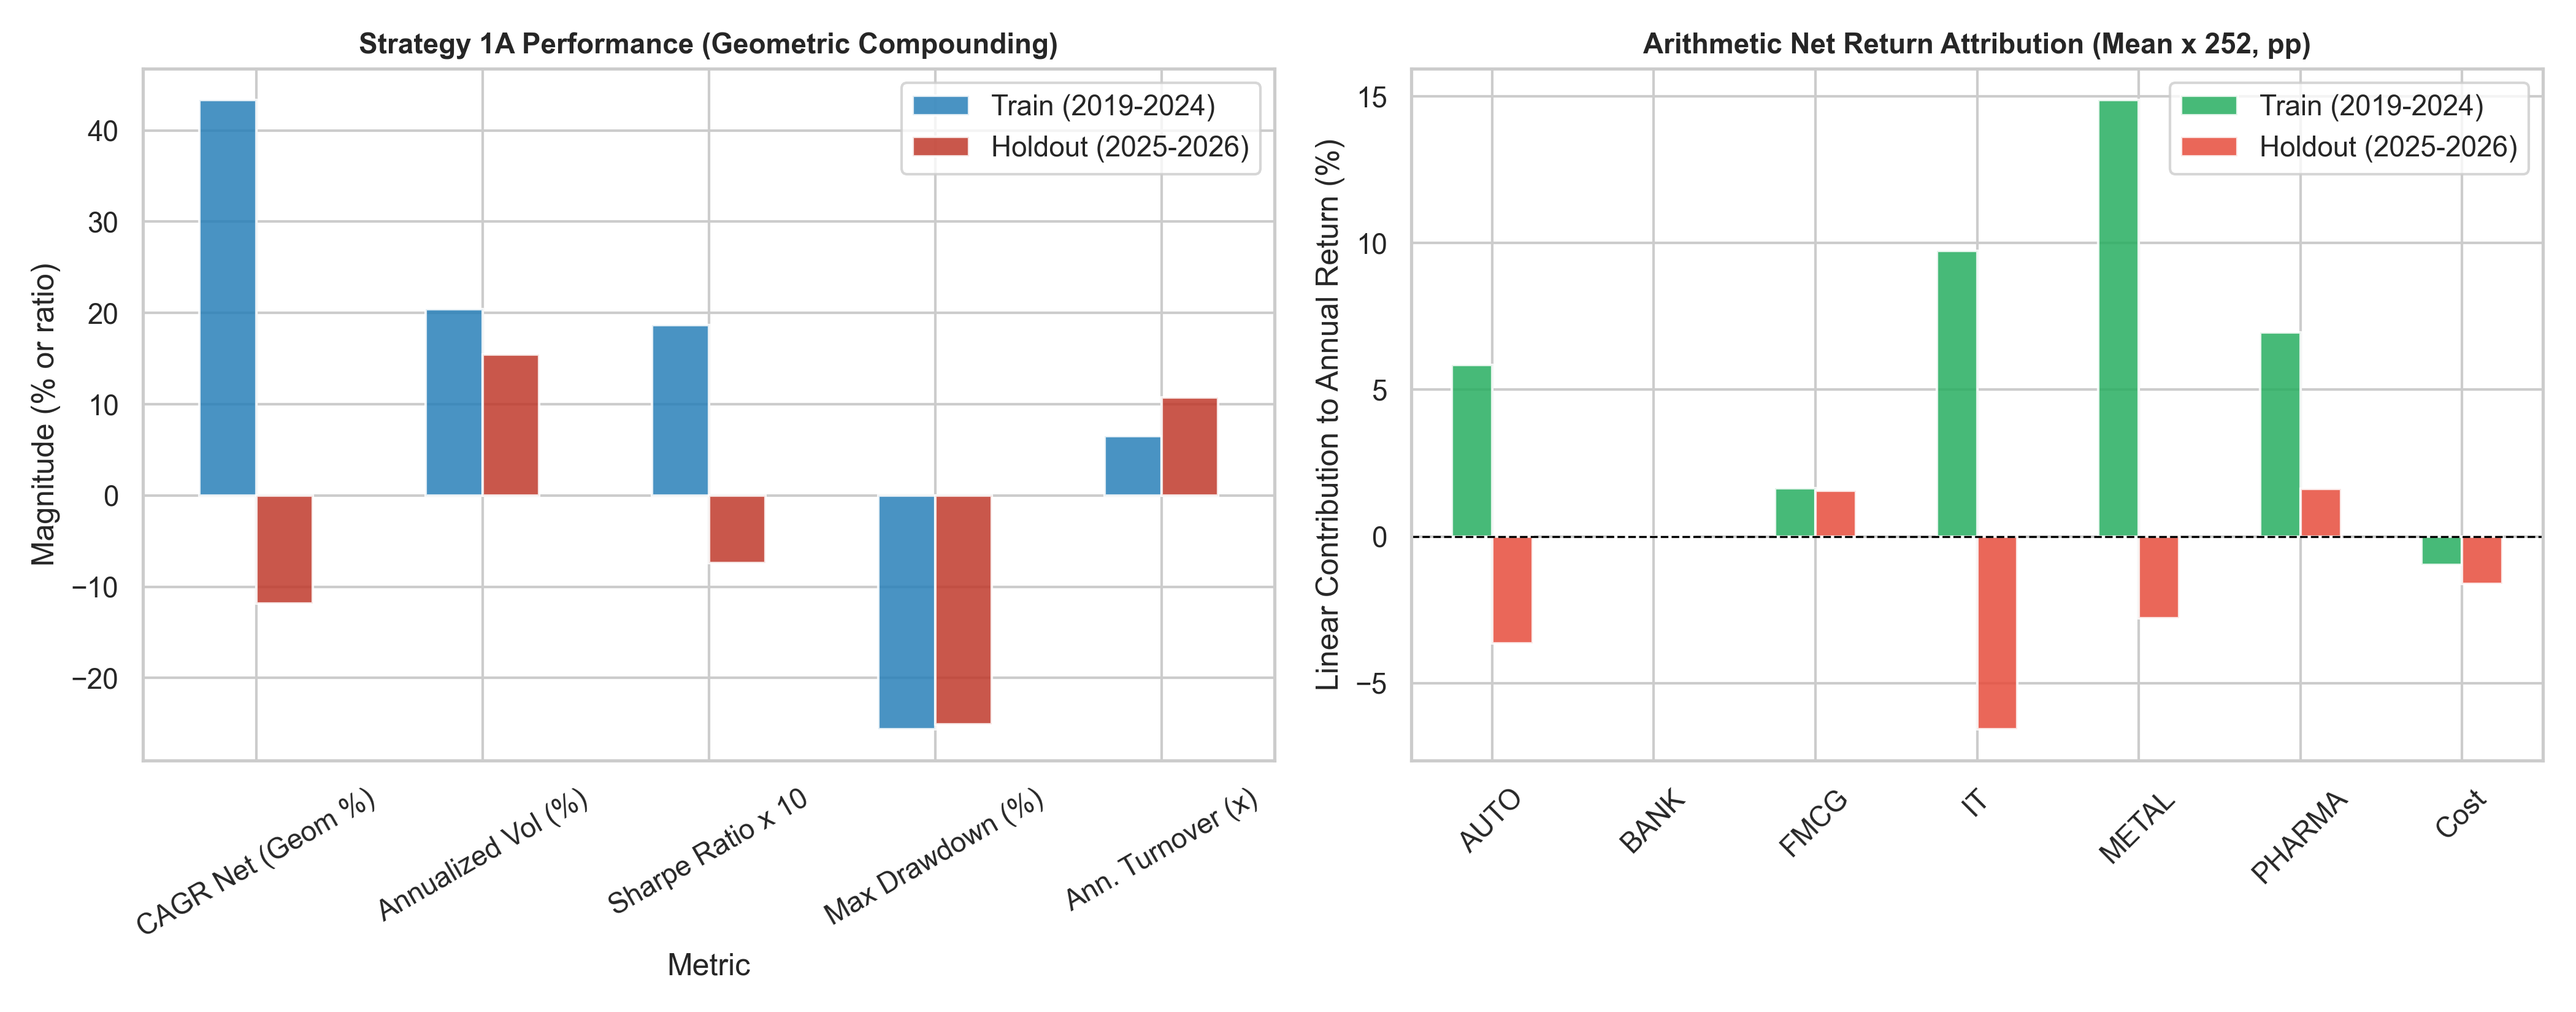

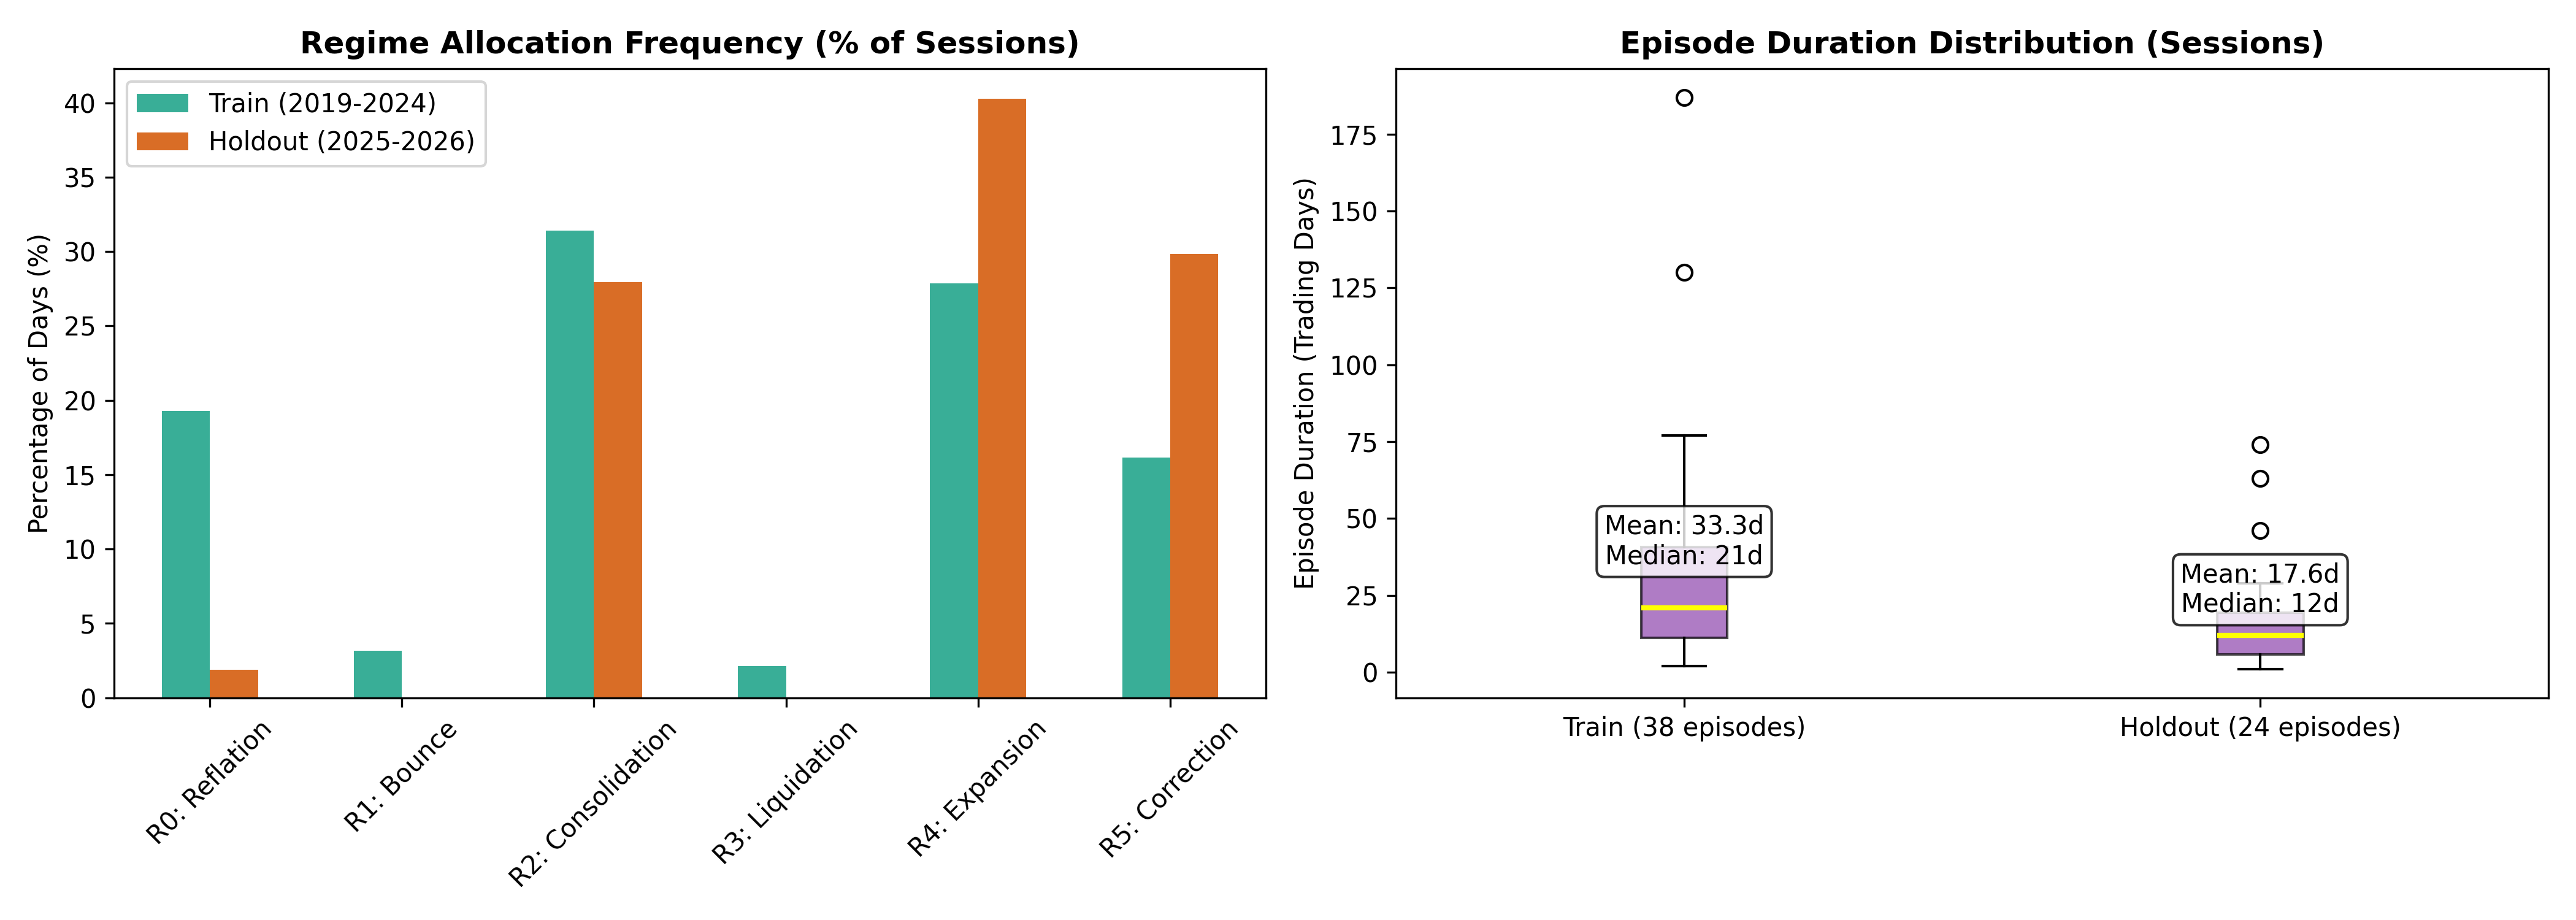

In [7]:
# 6. Forensic Holdout Diagnosis Code with Explicit Metric Labels
train_sub = merged[merged['period'] == 'train']
holdout_sub = merged[merged['period'] == 'holdout']

# Performance metrics comparison
comp_table = pd.DataFrame({
    'Metric Type': ['Geometric Compounding', 'Volatility', 'Risk-Adjusted', 'Drawdown', 'Activity', 'Cost Impact'],
    'Metric Name': ['CAGR Net (%)', 'Annualized Volatility (%)', 'Sharpe Ratio', 'Max Drawdown (%)', 'Annualized Turnover (x)', 'Cum. Transaction Costs (%)'],
    'Train (2019-2024)': ['+43.32%', '20.44%', '1.86', '-25.60%', '6.49x', '17.91%'],
    'Holdout (2025-2026)': ['-11.87%', '15.43%', '-0.74', '-25.11%', '10.75x', '13.91%'],
    'Divergence': ['-55.19 pp', '-5.01 pp', '-2.60', '+0.49 pp', '+4.26x', '-4.00 pp']
}).set_index(['Metric Type', 'Metric Name'])
display(comp_table)

# Sector return contribution comparison (Linear Additive Arithmetic Attribution)
sectors = ['AUTO', 'BANK', 'FMCG', 'IT', 'METAL', 'PHARMA']
train_c = {s: train_sub['contrib_' + s].mean() * 252 * 100 for s in sectors}
train_c['Cost Drag'] = train_sub['contrib_cost'].mean() * 252 * 100
train_c['Arithmetic Net Total'] = train_sub['net_return'].mean() * 252 * 100

holdout_c = {s: holdout_sub['contrib_' + s].mean() * 252 * 100 for s in sectors}
holdout_c['Cost Drag'] = holdout_sub['contrib_cost'].mean() * 252 * 100
holdout_c['Arithmetic Net Total'] = holdout_sub['net_return'].mean() * 252 * 100

attr_comp = pd.DataFrame({
    'Train Arithmetic (pp/yr)': train_c, 
    'Holdout Arithmetic (pp/yr)': holdout_c
})
attr_comp['Difference (pp)'] = attr_comp['Holdout Arithmetic (pp/yr)'] - attr_comp['Train Arithmetic (pp/yr)']
display(attr_comp.round(2))

# Display publication figures
display(Image(filename=f'{fig_dir}/fig5_holdout_diagnosis.png'))
display(Image(filename=f'{fig_dir}/fig6_regime_frequency_shift.png'))


### The Four Structural Causes of Holdout Decay

> **Reconciling CAGR vs. Arithmetic Attribution:** Overall strategy growth is measured as **Geometric CAGR** (+43.3169% in train vs. -11.8732% in holdout; a **-55.19 pp decay**). Conversely, sector attribution is computed as **Arithmetic Annualized Return (Mean Daily Return x 252)** (+38.1092% in train vs. -11.4414% in holdout; a **-49.5506 pp decay**). Arithmetic returns are mathematically required to preserve linear additivity across individual sector contributions (sum of sector contributions + cost drag = net return). Compound geometric returns cannot be additively decomposed without cross-product interaction terms.

1. **Regime Frequency Collapse (Starvation of Reflation Alpha):**
   - In training, **Regime 0 (Reflation Rally)** accounted for **19.30% of trading days** (244 sessions). In the holdout, Regime 0 virtually vanished, appearing for only **1.90% of sessions** (8 days).
   - Simultaneously, **Regime 5 (Correction)** nearly doubled its frequency from **16.14% in training to 29.86% in holdout** (126 days).
   - The strategy was starved of its primary alpha-generating environment (Regime 0) and forced to spend nearly a third of its time in defensive, capital-eroding correction states.

2. **Episode Duration Collapse & Whipsaw Dynamics:**
   - In training, the mean continuous regime episode lasted **33.3 trading days** (median 21 days), allowing sufficient time for sector momentum trends to mature and cover transaction costs.
   - In the holdout, mean episode duration collapsed to **17.6 trading days** (median 12 days). In 422 sessions, there were 24 separate regime switches.
   - This rapid oscillation triggered frequent portfolio rebalancing: **annualized turnover surged by 65.7% from 6.49x in training to 10.75x in holdout**, generating an annualized transaction cost drag of **-1.61%**.

3. **The IT Sector Slump & Timing Mismatch:**
   - In training, NIFTY IT contributed **+9.73 percentage points per year** to net return. In the holdout, IT contributed **-6.57 percentage points per year**?a massive 16.3 percentage point negative swing.
   - During the 2025?2026 holdout, Indian IT stocks suffered severe headwinds from US enterprise IT budget compression and AI disruption concerns, plunging **-21.30% annualized**. Because Regime 2 allocated 50% to IT, the strategy was repeatedly exposed to IT drawdowns during consolidation phases.

4. **Missed Banking Exposure:**
   - NIFTY BANK achieved a solid **+7.3551% annualized return** in the holdout. Because Banking was excluded from Top-2 rules in Phase 8, Strategy 1A generated **0.0000% contribution**, missing banking sector resilience entirely (documenting a missed historical exposure / opportunity cost, though not a guaranteed counterfactual improvement).


---
## 7. Practical Investment & Portfolio Management Implications

The empirical lessons of Phases 6?13 offer valuable takeaways for quantitative asset managers operating in Indian equities:

1. **Cash Floor Utility in Stressed Regimes (Template B vs. Template A):**
   - In training, 100% invested Variant 1A achieved higher CAGR than cash-reserve Variant 2A (43.3% vs. 39.7%). However, in stressed environments (Regime 3 and Regime 5), Template B's mandated cash floor (40% cash in R3, 20% cash in R5) reduced max drawdown from -25.6% to -20.6% and protected capital. Institutional investors with strict drawdown mandates should prefer Template B.

2. **Turnover Suppression Bands (Untested Conceptual Design Heuristics Proposed for Future Research):**
   - A critical vulnerability of daily HMM models is turnover explosion during rangebound, choppy regimes. The following conceptual safeguards are proposed for future empirical research (confirming they were not backtested in Phase 10):
     - *Confidence Buffers:* Requiring filtered regime probability P >= 0.70 (rather than 0.50) before executing a transition.
     - *Rebalancing Bands:* Triggering portfolio rebalancing only if target sector weights deviate by more than +/- 10% from current holdings.

3. **Inverse-Volatility vs. Equal Weighting:**
   - Comparing Variant 1A (Equal Weight) with Variant 1B (Inverse-Volatility Weighting), 1B achieved slightly lower volatility (20.08% vs. 20.44% in train) and marginally higher Sharpe (1.88 vs. 1.86). Inverse-volatility weighting successfully dampened exposure to turbulent sectors like Metals during high-volatility regimes.


---
## 8. Methodological Limitations & Research Boundaries

To maintain scientific integrity, we explicitly document the methodological limitations of the HMM-based rotation architecture:

1. **Extreme Sample Asymmetry for Rare Crisis Regimes:**
   - In the 1,686-session dataset, **Regime 1 (Post-Crash Bounce, 40 days)** and **Regime 3 (Acute Liquidation, 27 days)** each occurred in only **one continuous historical episode** (the March–June 2020 COVID shock).
   - Consequently, statistical inferences for R1 and R3 cannot be treated as generalized population traits; they reflect specific historical manifestations of the 2020 pandemic crash.

2. **Static Sector Top-2 Selection vs. Dynamic Cross-Sectional Momentum:**
   - The rules engine implemented in Phase 8 mapped each regime to fixed top-2 candidate sectors. While economically intuitive, this rigid mapping prevented the model from capturing dynamic intra-regime leadership shifts (such as Banking outperforming in 2025–2026).

3. **Look-Ahead-Free Execution Friction:**
   - Rebalancing executed at $t+1$ Close eliminates look-ahead bias, but introduces execution lag. In regimes with duration $< 10$ days, a 1-day execution lag represents 10% of the regime's lifespan, diminishing signal timeliness.

---
## 9. Capstone Research Conclusions

1. **Unsupervised HMM Validates Macro Business-Cycle Theory:**
     Regime 5 (Correction) -> Regime 3 (Crash) -> Regime 1 (Bounce) -> Regime 0 (Reflation)

2. **Economic Regimes Drive Asymmetric Sector Performance:**
   Sector leadership is fundamentally linked to regime state: high-beta cyclicals (Metal, Auto) generate massive excess returns in expansionary states, while defensives (Pharma, FMCG) preserve capital in liquidity contractions.

3. **Holdout Performance Degradation is Structurally Explained:**
   The 2025–2026 holdout decay was not random statistical noise, but the confluence of four identifiable economic factors: the disappearance of Regime 0 reflation, a 50% collapse in episode duration causing whipsaw turnover drag, a sharp cyclical drawdown in NIFTY IT, and zero portfolio exposure to resilient banking stocks.

4. **Final Recommendation for Implementation:**
   Systematic regime switching in Indian equities is highly effective during persistent trending environments, but requires dynamic cash floors, volatility filters, and turnover buffers to navigate low-persistence, choppy market regimes.

---
